# 03 · Baseline: handcrafted features + LightGBM

**Goal:** a fast, interpretable benchmark the CNN has to beat. Each feature describes a pattern the way an engineer would: *where* the failing dies are (rings, edge sectors) and *what shape* the biggest failing cluster has (size, position, elongation).

**Setup** (decided in notebook 01)
- 172,950 labeled wafers, resized to 64x64 with nearest-neighbour
- train / val / test split stratified by class and **grouped by lot** (no lot in two splits)
- metrics: macro-F1 (headline), per-class recall, and *yield-loss capture*: the share of failing dies on patterned wafers whose pattern was identified correctly

Run `python scripts/prepare_wm811k.py` once before this notebook.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wafer import evaluate
from wafer.data import FAILURE_TYPES
from wafer.features import extract_features
from wafer.preprocess import load_dataset

FIG_DIR = Path('../reports/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 3)

In [2]:
ds = load_dataset()
tr, va, te = (ds['split'] == s for s in ('train', 'val', 'test'))
pd.crosstab(np.array(FAILURE_TYPES)[ds['y']], ds['split'])[['train', 'val', 'test']]

col_0,train,val,test
row_0,,,
Center,3005,430,859
Donut,388,56,111
Edge-Loc,3632,519,1038
Edge-Ring,6776,968,1936
Loc,2514,360,719
Near-full,104,15,30
Random,606,87,173
Scratch,834,120,239
none,103219,14732,29480


## 1. Feature extraction (~1 minute)

In [3]:
%%time
F = extract_features(ds['X'])
F.describe().T

CPU times: total: 28.2 s
Wall time: 28.2 s


,count,mean,std,min,25%,50%,75%,max
fail_ratio,172950.0,0.118,0.074,0.0,0.069,0.105,0.151,1.000
ring0_fail,172950.0,0.144,0.142,0.0,0.056,0.113,0.194,1.000
ring1_fail,172950.0,0.092,0.097,0.0,0.037,0.068,0.115,1.000
ring2_fail,172950.0,0.083,0.077,0.0,0.038,0.064,0.107,1.000
ring3_fail,172950.0,0.085,0.068,0.0,0.042,0.069,0.110,1.000
ring4_fail,172950.0,0.170,0.094,0.0,0.104,0.157,0.219,1.000
edge_sector_max,172950.0,0.283,0.142,0.0,0.183,0.264,0.358,1.000
edge_sector_min,172950.0,0.080,0.074,0.0,0.029,0.063,0.108,1.000
edge_sector_std,172950.0,0.065,0.036,0.0,0.042,0.059,0.081,0.455
edge_uniformity,172950.0,0.259,0.168,0.0,0.138,0.245,0.362,1.000


## 2. Train LightGBM with early stopping on the validation split

In [4]:
%%time
clf = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=63,
    class_weight='balanced', subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1,
)
clf.fit(
    F[tr], ds['y'][tr], eval_set=[(F[va], ds['y'][va])],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
print('best iteration:', clf.best_iteration_)

F:\claude\wafer-yield-portfolio\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best iteration: 355
CPU times: total: 1min 8s
Wall time: 8.66 s


## 3. Test-set results

In [5]:
pred = clf.predict(F[te])
summary = evaluate.summarize(ds['y'][te], pred, ds['n_fail'][te], name='LightGBM')
summary

macro_f1              0.861
weighted_f1           0.968
accuracy              0.967
yield_loss_capture    0.921
Name: LightGBM, dtype: float64

In [6]:
evaluate.per_class_report(ds['y'][te], pred)

,precision,recall,f1-score,support
Center,0.895,0.905,0.900,859.0
Donut,0.858,0.820,0.839,111.0
Edge-Loc,0.732,0.868,0.794,1038.0
Edge-Ring,0.978,0.977,0.978,1936.0
Loc,0.669,0.762,0.713,719.0
Near-full,0.909,1.000,0.952,30.0
Random,0.932,0.867,0.898,173.0
Scratch,0.679,0.699,0.689,239.0
none,0.990,0.980,0.985,29480.0


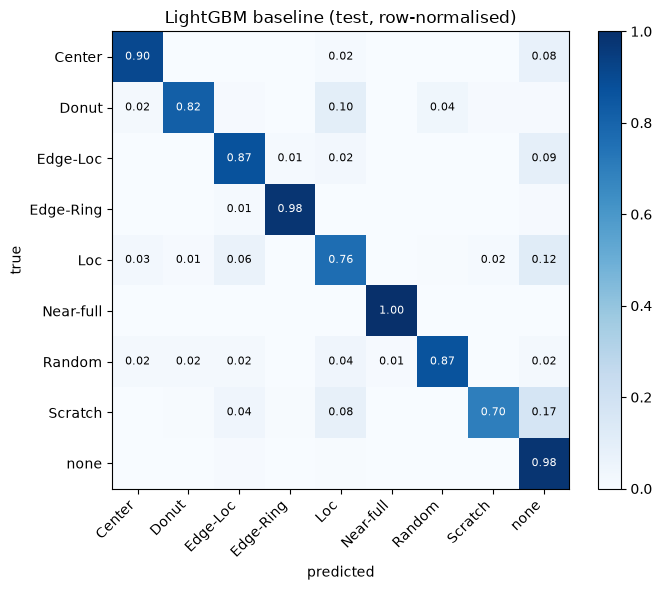

In [7]:
fig = evaluate.plot_confusion(ds['y'][te], pred, 'LightGBM baseline (test, row-normalised)')
fig.savefig(FIG_DIR / 'baseline_confusion.png', dpi=150)

## 4. Which features matter?

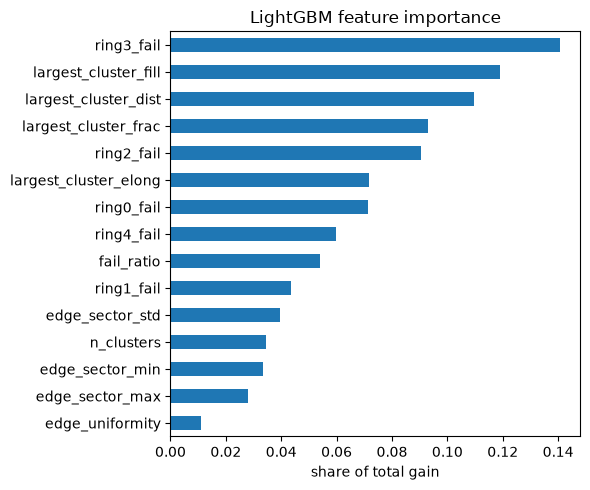

In [8]:
imp = pd.Series(clf.booster_.feature_importance('gain'), index=F.columns)
ax = (imp / imp.sum()).sort_values().plot.barh(figsize=(6, 5))
ax.set_xlabel('share of total gain'); ax.set_title('LightGBM feature importance')
plt.tight_layout(); plt.savefig(FIG_DIR / 'baseline_importance.png', dpi=150)

## 5. Save results for the README

In [9]:
report = evaluate.per_class_report(ds['y'][te], pred)
results = {
    'model': 'LightGBM on 20 handcrafted features',
    **summary.round(4).to_dict(),
    'recall_per_class': report['recall'].round(4).to_dict(),
}
Path('../reports/results_baseline.json').write_text(json.dumps(results, indent=2))
results

{'model': 'LightGBM on 20 handcrafted features',
 'macro_f1': 0.8608,
 'weighted_f1': 0.9678,
 'accuracy': 0.9669,
 'yield_loss_capture': 0.9211,
 'recall_per_class': {'Center': 0.9045,
  'Donut': 0.8198,
  'Edge-Loc': 0.868,
  'Edge-Ring': 0.9773,
  'Loc': 0.7622,
  'Near-full': 1.0,
  'Random': 0.8671,
  'Scratch': 0.6987,
  'none': 0.9797}}

## Findings

_Send the outputs above to Claude to write this section._